# Recomendação de culturas agrícolas com Perceptron e MLP

## 1. Introdução

Características do solo e condições climáticas influenciam o cultivo agrícola. Neste trabalho, usamos uma base pública para estudar como redes neurais podem apoiar a identificação de culturas a partir dessas características.

O problema é de **classificação multiclasse**: receber sete medidas como entrada e prever uma entre 22 culturas presentes na base. Comparamos um **Perceptron**, que aprende decisões lineares, com uma **MLP**, que possui camadas ocultas e pode aprender relações não lineares.

**Objetivo:** comparar o desempenho dos dois modelos, identificar seus principais erros e discutir possibilidades de aplicação na Engenharia.


## 2. Bibliotecas

Usamos Pandas e NumPy para manipular os dados, Matplotlib para gerar gráficos e Scikit-learn para preparar os dados, treinar e avaliar os modelos.


In [ ]:
%pip install -q numpy pandas matplotlib scikit-learn


In [ ]:
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Perceptron
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay
)

print("Python:", sys.version.split()[0])
print("NumPy:", np.__version__, "| Pandas:", pd.__version__)
print("Scikit-learn:", sklearn.__version__)
print("Matplotlib:", plt.matplotlib.__version__)


Python: 3.13.18
NumPy: 2.4.6 | Pandas: 2.2.3
Scikit-learn: 1.6.1
Matplotlib: 3.10.0


## 3. Base de dados

O [Crop Recommendation Dataset](https://www.kaggle.com/datasets/atharvaingle/crop-recommendation-dataset), publicado por Atharva Ingle no Kaggle, contém 2.200 registros, com 100 exemplos de cada uma das 22 culturas. Segundo os metadados consultados em 26/10/2026, a versão 1 tem licença Apache 2.0 e combina dados de chuva, clima e fertilizantes da Índia.

| Coluna | Significado |
|---|---|
| `N` | Proporção de nitrogênio no solo |
| `P` | Proporção de fósforo no solo |
| `K` | Proporção de potássio no solo |
| `temperature` | Temperatura em graus Celsius |
| `humidity` | Umidade relativa do ar em porcentagem |
| `ph` | pH do solo |
| `rainfall` | Precipitação em milímetros |
| `label` | Cultura indicada (alvo da classificação) |

Antes de usar medições externas, é preciso confirmar as unidades de N, P e K e o período de acúmulo da precipitação, que a fonte não detalha.

Ao executar o notebook, baixamos o ZIP público do Kaggle e lemos o CSV com Pandas, inclusive no Google Colab.


In [ ]:
url = "https://www.kaggle.com/api/v1/datasets/download/atharvaingle/crop-recommendation-dataset"
dados = pd.read_csv(url, compression="zip")

display(dados.head())
print("Dimensões da base:", dados.shape)
print("Quantidade de culturas:", dados["label"].nunique())


,N,P,K,temperature,humidity,ph,rainfall,label
0,90,42,43,20.879744,82.002744,6.502985,202.935536,rice
1,85,58,41,21.770462,80.319644,7.038096,226.655537,rice
2,60,55,44,23.004459,82.320763,7.840207,263.964248,rice
3,74,35,40,26.491096,80.158363,6.980401,242.864034,rice
4,78,42,42,20.130175,81.604873,7.628473,262.717340,rice


Dimensões da base: (2200, 8)
Quantidade de culturas: 22


### 3.1. Conferência dos dados

Conferimos os tipos das colunas. A base tem a mesma quantidade de exemplos por cultura e está livre de valores ausentes e duplicatas. Mantivemos os registros originais.


In [ ]:
print("Tipos das colunas:")
print(dados.dtypes)
print("\nValores ausentes:")
print(dados.isna().sum())
print("\nLinhas duplicadas:", dados.duplicated().sum())

# Verifica se as sete entradas são numéricas e finitas.
entradas = dados.drop(columns="label")
assert np.isfinite(entradas.to_numpy()).all(), "Há valores não numéricos ou não finitos."
assert not dados.isna().any().any(), "Há dados ausentes para investigar."
assert not dados.duplicated().any(), "Há duplicatas para investigar antes da divisão."


Tipos das colunas:
N                int64
P                int64
K                int64
temperature    float64
humidity       float64
ph             float64
rainfall       float64
label           object
dtype: object

Valores ausentes:
N              0
P              0
K              0
temperature    0
humidity       0
ph             0
rainfall       0
label          0
dtype: int64

Linhas duplicadas: 0


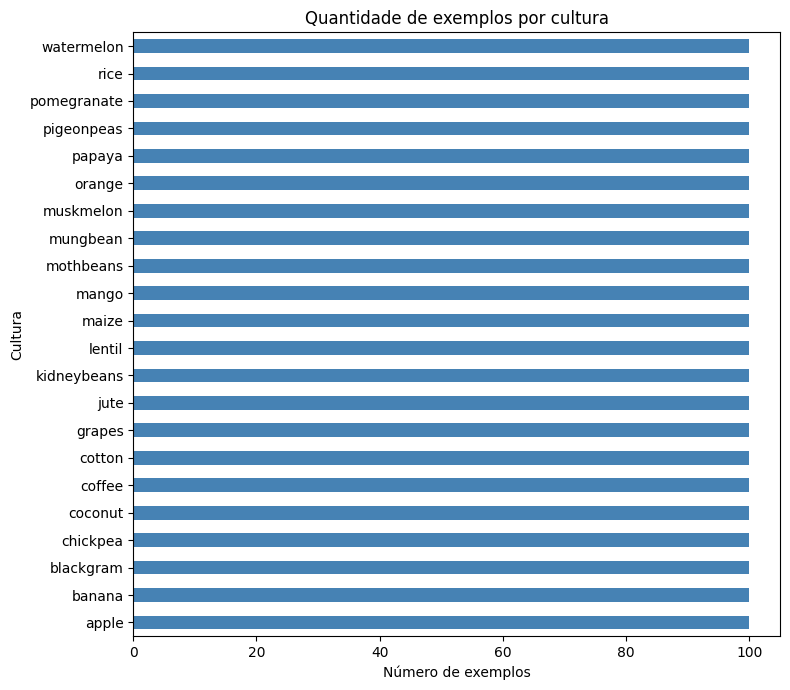

In [ ]:
contagem = dados["label"].value_counts().sort_index()
contagem.plot.barh(figsize=(8, 7), color="steelblue")
plt.title("Quantidade de exemplos por cultura")
plt.xlabel("Número de exemplos")
plt.ylabel("Cultura")
plt.tight_layout()
plt.show()


## 4. Metodologia e preparação

### 4.1. Divisão de 70% para treino e 30% para teste

As sete medidas formam `X`, e a coluna `label` é o alvo `y`. A divisão estratificada reserva **1.540 exemplos para treino** e **660 para teste**, com 70 e 30 exemplos por cultura, respectivamente.

Os dois modelos usam a mesma divisão, reproduzível com `random_state=42`. Fixamos as configurações antes de avaliar os modelos no teste. Como usamos uma única divisão, sem busca de hiperparâmetros ou validação cruzada, a avaliação é inicial e não mede a variação entre partições.


In [ ]:
X = dados.drop(columns="label")
y = dados["label"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)

print("Treino:", X_train.shape, "| Teste:", X_test.shape)
print("Exemplos de cada cultura no treino:", y_train.value_counts().unique())
print("Exemplos de cada cultura no teste:", y_test.value_counts().unique())


Treino: (1540, 7) | Teste: (660, 7)
Exemplos de cada cultura no treino: [70]
Exemplos de cada cultura no teste: [30]


### 4.2. Análise das entradas do treino

As estatísticas e os histogramas do treino mostram que os atributos têm escalas e distribuições diferentes. Mantivemos valores extremos porque podem representar condições válidas.


,N,P,K,temperature,humidity,ph,rainfall
count,1540.00,1540.00,1540.00,1540.00,1540.00,1540.00,1540.00
mean,50.46,53.29,48.13,25.58,71.44,6.47,103.35
std,37.03,32.84,50.72,5.13,22.29,0.78,54.97
min,0.00,5.00,5.00,8.83,14.26,3.50,20.21
25%,21.00,28.00,20.00,22.75,60.16,5.96,64.70
50%,37.00,51.00,32.00,25.50,80.55,6.43,94.72
75%,84.00,68.00,48.00,28.48,89.87,6.93,123.61
max,140.00,145.00,205.00,43.36,99.98,9.94,298.56


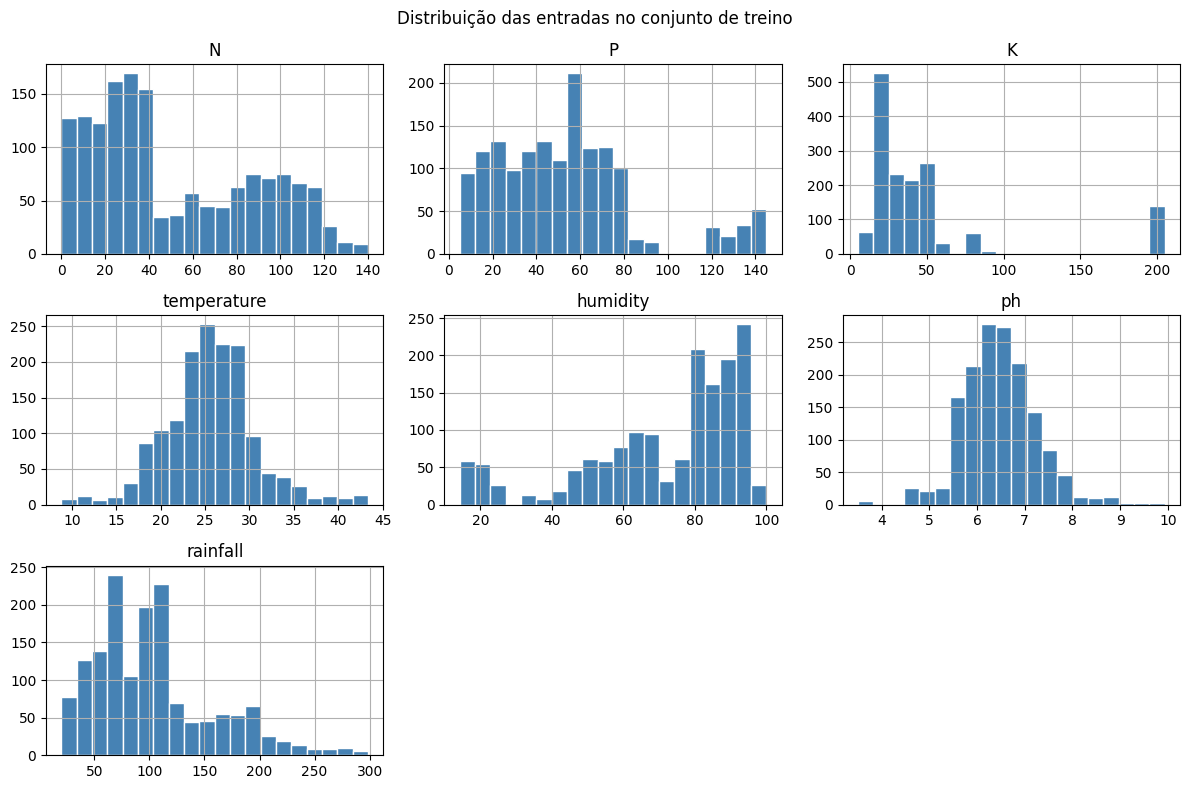

In [ ]:
display(X_train.describe().round(2))
X_train.hist(bins=20, figsize=(12, 8), color="steelblue", edgecolor="white")
plt.suptitle("Distribuição das entradas no conjunto de treino")
plt.tight_layout()
plt.show()


### 4.3. Padronização

O `StandardScaler` calcula $z=(x-\mu)/\sigma$ para reduzir o efeito das diferenças de escala nas atualizações dos pesos.

Calculamos as médias e os desvios no treino e os reutilizamos no teste com `transform`. Os rótulos ficam como texto, pois o Scikit-learn os codifica internamente.


In [ ]:
scaler = StandardScaler()
X_train_pad = scaler.fit_transform(X_train)
X_test_pad = scaler.transform(X_test)


## 5. Implementação das redes neurais

### 5.1. Perceptron

O Perceptron calcula o escore linear $s=\mathbf{w}^{T}\mathbf{x}+b$ e atualiza pesos e viés a partir dos erros de classificação. Treinamos um classificador por cultura contra as demais e prevemos a cultura com o maior escore.

Usamos o `Perceptron` do Scikit-learn com até 1.000 épocas, tolerância `1e-3` e semente fixa. O modelo serve de referência linear. Em dados sem separação linear, a convergência não é garantida.


In [ ]:
perceptron = Perceptron(max_iter=1000, tol=1e-3, random_state=42)
perceptron.fit(X_train_pad, y_train)
print("Épocas do Perceptron:", perceptron.n_iter_)


Épocas do Perceptron: 23


### 5.2. MLP — Perceptron de múltiplas camadas

A arquitetura **7 → 16 → 16 → 22** tem sete entradas, duas camadas ocultas com 16 neurônios cada e uma saída por cultura. A ativação ReLU, $f(x)=\max(0,x)$, permite aprender relações não lineares.

O `MLPClassifier` usa softmax na saída e ajusta os pesos com Adam para minimizar a entropia cruzada com regularização L2 (`alpha=0.0001`).

A taxa inicial de aprendizado é `0.001` e o limite é de 2.000 épocas. Com `early_stopping=False`, o critério de parada usa a perda de treino (`tol=1e-4` e `n_iter_no_change=20`).


In [ ]:
mlp = MLPClassifier(
    hidden_layer_sizes=(16, 16),
    activation="relu",
    solver="adam",
    alpha=0.0001,
    learning_rate_init=0.001,
    max_iter=2000,
    tol=1e-4,
    n_iter_no_change=20,
    early_stopping=False,
    random_state=42
)
mlp.fit(X_train_pad, y_train)
print("Épocas da MLP:", mlp.n_iter_)
print("Perda final de treino:", round(mlp.loss_, 4))


Épocas da MLP: 725
Perda final de treino: 0.0095


## 6. Avaliação e análise dos resultados

### 6.1. Comparação das métricas no teste

- **Acurácia** é a proporção de previsões corretas entre os 660 exemplos de teste.
- **Precisão** é a proporção de acertos entre as previsões de uma cultura.
- **Recall** é a proporção de exemplos de uma cultura que o modelo identifica corretamente.
- **F1** é a média harmônica de precisão e recall.

Calculamos precisão, recall e F1 por cultura e tiramos a média simples das 22 classes para obter cada métrica macro. Com `zero_division=0`, as razões indefinidas recebem zero.


In [ ]:
modelos = {"Perceptron": perceptron, "MLP": mlp}
previsoes = {}
linhas = []

for nome, modelo in modelos.items():
    predicao = modelo.predict(X_test_pad)
    previsoes[nome] = predicao
    linhas.append({
        "Modelo": nome,
        "Acurácia": accuracy_score(y_test, predicao),
        "Precisão macro": precision_score(y_test, predicao, average="macro", zero_division=0),
        "Recall macro": recall_score(y_test, predicao, average="macro", zero_division=0),
        "F1 macro": f1_score(y_test, predicao, average="macro", zero_division=0)
    })

resultados = pd.DataFrame(linhas).set_index("Modelo")
display(resultados.round(4))


,Acurácia,Precisão macro,Recall macro,F1 macro
Modelo,,,,
Perceptron,0.8530,0.8914,0.8530,0.8427
MLP,0.9924,0.9926,0.9924,0.9924


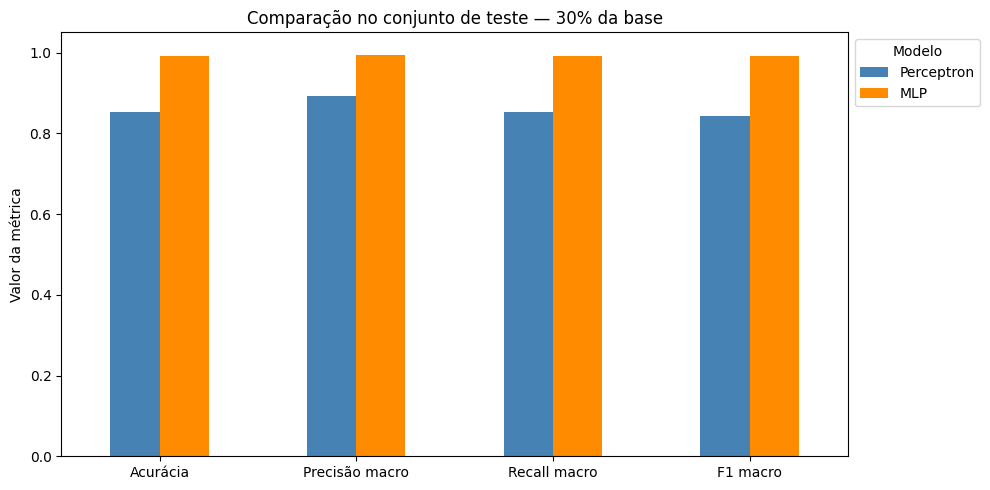

In [ ]:
ax = resultados.T.plot.bar(figsize=(10, 5), rot=0, color=["steelblue", "darkorange"])
ax.set_ylim(0, 1.05)
ax.set_ylabel("Valor da métrica")
ax.set_title("Comparação no conjunto de teste — 30% da base")
ax.legend(title="Modelo", loc="upper left", bbox_to_anchor=(1, 1))
plt.tight_layout()
plt.show()


### 6.2. Resultados por cultura e matrizes de confusão

O relatório apresenta precisão, recall, F1 e número de exemplos (`support`) por cultura. Nas duas matrizes, as linhas mostram a cultura real e as colunas, a prevista. Os acertos ficam na diagonal, e as culturas aparecem na mesma ordem.



 Perceptron
              precision    recall  f1-score   support

       apple      1.000     1.000     1.000        30
      banana      0.968     1.000     0.984        30
   blackgram      0.806     0.967     0.879        30
    chickpea      1.000     1.000     1.000        30
     coconut      1.000     1.000     1.000        30
      coffee      1.000     1.000     1.000        30
      cotton      0.900     0.900     0.900        30
      grapes      1.000     0.967     0.983        30
        jute      0.600     1.000     0.750        30
 kidneybeans      1.000     0.767     0.868        30
      lentil      1.000     0.367     0.537        30
       maize      0.900     0.900     0.900        30
       mango      1.000     1.000     1.000        30
   mothbeans      0.677     0.700     0.689        30
    mungbean      0.833     1.000     0.909        30
   muskmelon      1.000     0.233     0.378        30
      orange      1.000     0.700     0.824        30
      papaya  

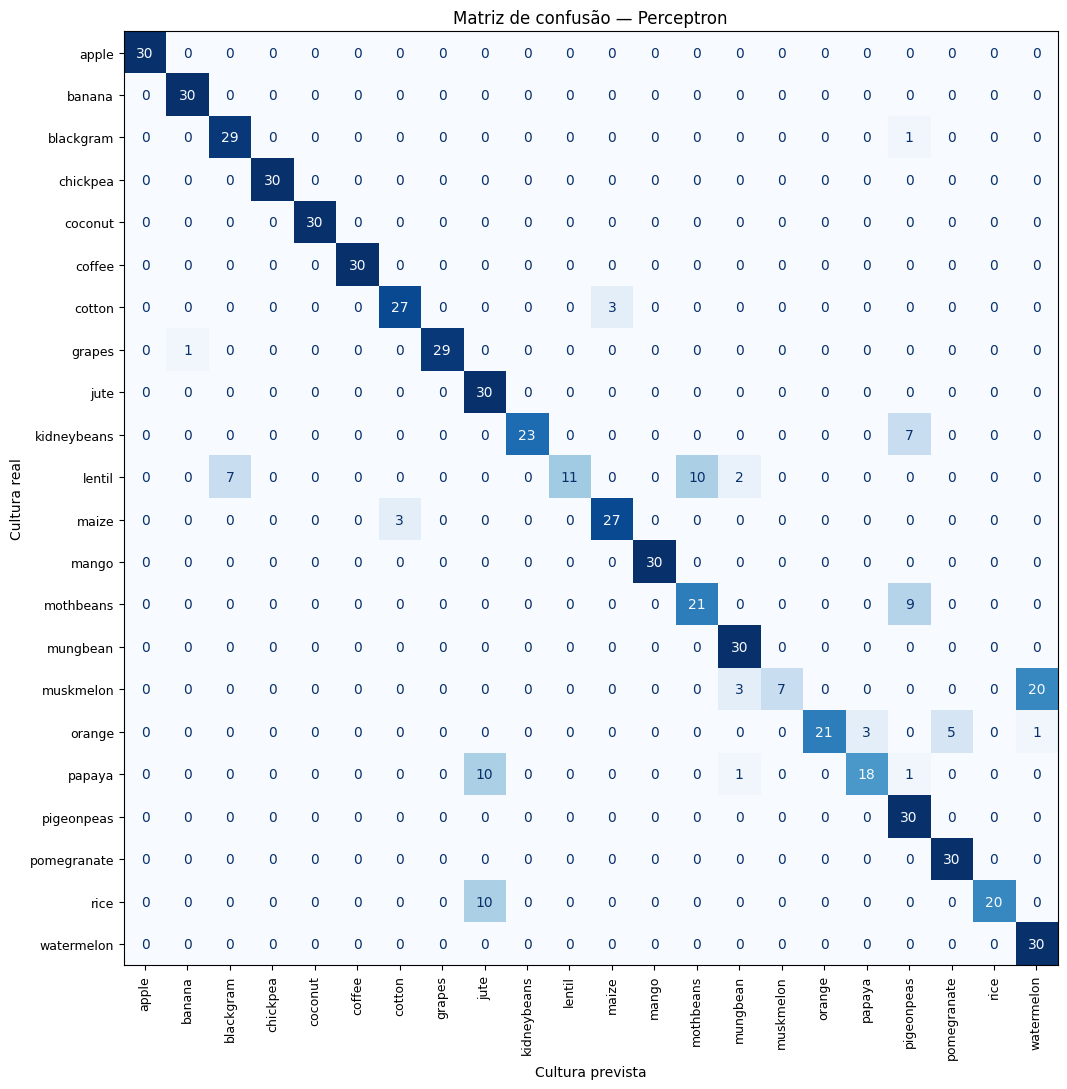


 MLP
              precision    recall  f1-score   support

       apple      1.000     1.000     1.000        30
      banana      1.000     1.000     1.000        30
   blackgram      1.000     1.000     1.000        30
    chickpea      1.000     1.000     1.000        30
     coconut      1.000     1.000     1.000        30
      coffee      1.000     1.000     1.000        30
      cotton      1.000     1.000     1.000        30
      grapes      1.000     1.000     1.000        30
        jute      0.906     0.967     0.935        30
 kidneybeans      1.000     1.000     1.000        30
      lentil      1.000     0.967     0.983        30
       maize      1.000     1.000     1.000        30
       mango      1.000     1.000     1.000        30
   mothbeans      0.968     1.000     0.984        30
    mungbean      1.000     1.000     1.000        30
   muskmelon      1.000     1.000     1.000        30
      orange      1.000     1.000     1.000        30
      papaya      1.0

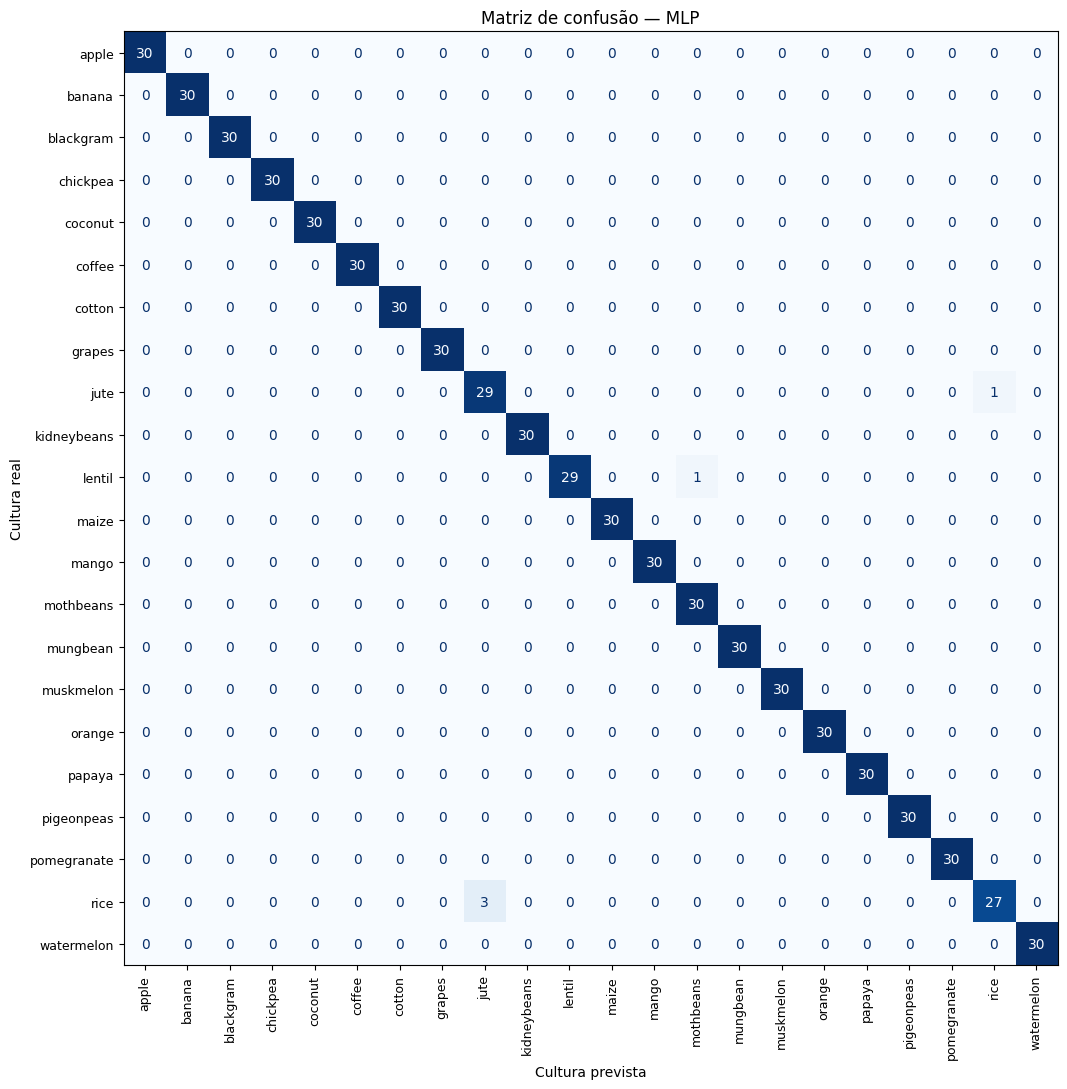

In [ ]:
classes = np.sort(y.unique())

for nome, predicao in previsoes.items():
    print("\n", nome)
    print(classification_report(y_test, predicao, labels=classes, digits=3, zero_division=0))

    fig, ax = plt.subplots(figsize=(12, 11))
    ConfusionMatrixDisplay.from_predictions(
        y_test, predicao, labels=classes, display_labels=classes,
        cmap="Blues", values_format="d", xticks_rotation=90,
        colorbar=False, ax=ax
    )
    ax.set_title(f"Matriz de confusão — {nome}")
    ax.set_xlabel("Cultura prevista")
    ax.set_ylabel("Cultura real")
    ax.tick_params(axis="both", labelsize=9)
    plt.tight_layout()
    plt.show()


### 6.3. Perda de treinamento da MLP

A curva mostra como a perda da MLP evolui durante o treino. Avaliamos a generalização no conjunto de teste. Perceptron e MLP usam objetivos de treinamento diferentes, o que impede a comparação direta de suas perdas.


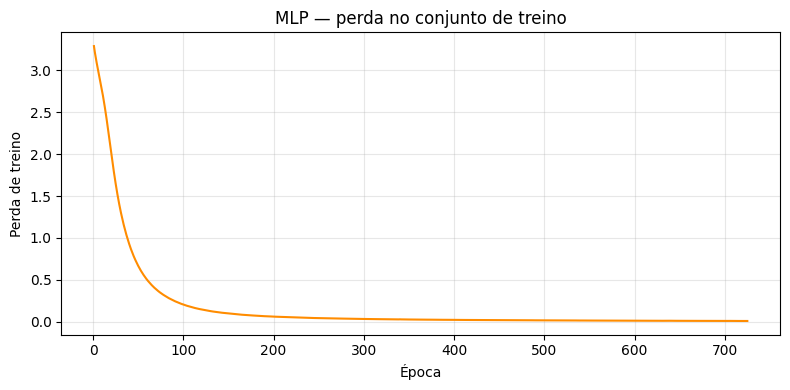

In [ ]:
plt.figure(figsize=(8, 4))
plt.plot(range(1, len(mlp.loss_curve_) + 1), mlp.loss_curve_, color="darkorange")
plt.title("MLP — perda no conjunto de treino")
plt.xlabel("Época")
plt.ylabel("Perda de treino")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


### 6.4. Principais erros

Agrupamos os erros por par de culturas para identificar quais trocas foram mais frequentes. Essa análise permite apontar dificuldades específicas sem esconder diferenças entre as classes em uma única acurácia.


In [ ]:
for nome, predicao in previsoes.items():
    comparacao = pd.DataFrame({"Real": y_test, "Prevista": predicao})
    erros = comparacao[comparacao["Real"] != comparacao["Prevista"]]
    print(f"\n{nome}: {len(erros)} erros em {len(y_test)} exemplos de teste")
    display(erros.value_counts().head(5).rename("Ocorrências").reset_index())



Perceptron: 97 erros em 660 exemplos de teste


,Real,Prevista,Ocorrências
0,muskmelon,watermelon,20
1,lentil,mothbeans,10
2,papaya,jute,10
3,rice,jute,10
4,mothbeans,pigeonpeas,9



MLP: 5 erros em 660 exemplos de teste


,Real,Prevista,Ocorrências
0,rice,jute,3
1,jute,rice,1
2,lentil,mothbeans,1


## 7. Discussão

Na execução registrada, o **Perceptron obteve acurácia de 85,30% e F1 macro de 0,8427**, com 97 erros em 660 exemplos. A **MLP obteve acurácia de 99,24% e F1 macro de 0,9924**, com cinco erros. A diferença de acurácia foi de **13,94 pontos percentuais**, favorável à MLP nesta divisão dos dados.

O Perceptron reconheceu perfeitamente algumas culturas, mas apresentou dificuldades importantes em outras. Por exemplo, classificou 20 exemplos de `muskmelon` como `watermelon`; o recall de `muskmelon` foi apenas 7/30, ou 23,33%. Para `lentil`, o recall foi 11/30, ou 36,67%. Isso mostra por que a acurácia global deve ser acompanhada por métricas por classe: uma média pode esconder falhas concentradas em determinadas culturas.

Na MLP, quatro dos cinco erros ocorreram entre `rice` e `jute`: três exemplos de arroz foram classificados como juta e um de juta como arroz. O outro erro foi de `lentil` para `mothbeans`. As matrizes mostram uma diagonal mais concentrada na MLP, coerente com suas métricas superiores.

O resultado é compatível com a vantagem de representar relações não lineares entre os atributos. Entretanto, não demonstra que todo classificador linear seria inadequado: taxa de aprendizado, regularização e outros ajustes também influenciam o treinamento. Como usamos configurações fixas, a comparação vale para **estes dois modelos e estas condições**, sem afirmar que encontramos a melhor configuração possível. A MLP terminou após 725 épocas, com perda de treino próxima de 0,0095; uma perda pequena, isoladamente, não comprova generalização.

**Limitações e melhorias:** a base é pequena, balanceada e formada a partir de dados referentes à Índia. Não conhecemos suficientemente o processo de amostragem e a independência entre registros. Uma divisão aleatória pode colocar condições semelhantes nos dois conjuntos e não comprova desempenho em novas regiões ou safras. Há apenas 30 exemplos de teste por cultura, portanto cada erro muda seu recall em 3,33 pontos percentuais. Também não medimos a variação entre outras divisões e inicializações. Em uma continuação, seria adequado aplicar validação cruzada apenas no desenvolvimento, testar outras sementes e avaliar dados locais independentes, mantendo um teste final reservado.


## 8. Conclusão e relação com Engenharia

No teste, a MLP teve maior acurácia e F1 macro. O Perceptron serviu de referência linear, e a análise por cultura mostrou onde cada modelo errou.

Na agricultura de precisão, um protótipo de apoio à decisão poderia coletar dados do solo e do ambiente, conferir as medições e aplicar a padronização do treino antes de classificar. Instrumentação, aquisição de dados e integração de sensores fazem parte desse fluxo.

O experimento demonstra a viabilidade computacional na base avaliada. Os modelos aprendem a prever os rótulos da base. O uso em campo exigiria padronizar medições, calibrar sensores e validar o sistema com profissionais da área em condições locais diferentes das de treino, considerando produtividade, lucro e critérios agronômicos.


## 9. Referências

- INGLE, Atharva. [Crop Recommendation Dataset](https://www.kaggle.com/datasets/atharvaingle/crop-recommendation-dataset). Kaggle. [Metadados oficiais](https://www.kaggle.com/api/v1/datasets/view/atharvaingle/crop-recommendation-dataset), consultados em 26/10/2026.
- SCIKIT-LEARN. [Perceptron](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.Perceptron.html).
- SCIKIT-LEARN. [MLPClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.neural_network.MLPClassifier.html) e [redes neurais supervisionadas](https://scikit-learn.org/stable/modules/neural_networks_supervised.html).
- SCIKIT-LEARN. [Pré-processamento e prevenção de vazamento de dados](https://scikit-learn.org/stable/common_pitfalls.html).
- Materiais da disciplina: **Laboratório 1 — Perceptron: RNA simples e linear** e **Laboratório 2 — MLP**.

As versões utilizadas aparecem no início do notebook. A semente fixa torna a execução repetível nas mesmas condições; versões de bibliotecas e ambientes diferentes podem produzir pequenas variações.
